# Patient pathways and hospital resources: a process mining case study

**Goal:** reconstruct how patients move through a hospital from an event log, measure how long each step takes, see how busy each member of staff is, and compare process discovery algorithms.

**Data:** an artificial hospital event log of 100 patients and 690 events from the open [process mining in healthcare tutorial](https://gitlab.com/healthcare2/process-mining-tutorial). It is downloaded at run time and not redistributed here.

**Privacy:** staff names in the log are replaced with pseudonyms (Doctor 1, Nurse 1, …).

**Tools:** `pandas`, `matplotlib` and [`pm4py`](https://pm4py.fit.fraunhofer.de/) for discovery and conformance checking.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pm4py

DATA_URL = "https://gitlab.com/healthcare2/process-mining-tutorial/-/raw/master/ArtificialPatientTreatment.csv"
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)

INK, MUTED, GRID, ACCENT, SOFT = "#1d1d1f", "#6e6e73", "#e5e5ea", "#2a78d6", "#b9c6d6"
plt.rcParams.update({
    "font.size": 10, "text.color": INK, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "savefig.dpi": 170, "savefig.bbox": "tight", "savefig.facecolor": "white",
})

## 1. Preparing the event log

In [2]:
raw = pd.read_csv(DATA_URL, skipinitialspace=True)
raw.columns = [c.strip() for c in raw.columns]
df = raw.rename(columns={"patient": "case:concept:name", "action": "concept:name", "DateTime": "time:timestamp"})
df = df.apply(lambda s: s.str.strip() if s.dtype == "object" else s)
df["time:timestamp"] = pd.to_datetime(df["time:timestamp"])

# Pseudonymise staff: replace personal names with role + number (ordered by workload)
def pseudonymise(resources):
    mapping, counters = {}, {}
    for r in resources.value_counts().index:
        role = "Doctor" if r.startswith("Dr.") else "Nurse" if r.startswith("Nurse") else None
        if role:
            counters[role] = counters.get(role, 0) + 1
            mapping[r] = f"{role} {counters[role]}"
    return resources.replace(mapping)
df["org:resource"] = pseudonymise(df["org:resource"])
df = df.sort_values(["case:concept:name", "time:timestamp"]).reset_index(drop=True)
df["relative_days"] = (df["time:timestamp"] - df.groupby("case:concept:name")["time:timestamp"].transform("min")).dt.total_seconds() / 86400
log = pm4py.format_dataframe(df, case_id="case:concept:name", activity_key="concept:name", timestamp_key="time:timestamp")
print(f"{df['case:concept:name'].nunique()} patients, {len(df)} events, {df['concept:name'].nunique()} activities, {df['org:resource'].nunique()} resources")
df.head()

100 patients, 690 events, 8 activities, 13 resources


,case:concept:name,concept:name,org:resource,time:timestamp,relative_days
0,patient 0,First consult,Doctor 1,2017-01-02 11:40:11,0.000000
1,patient 0,Blood test,Lab,2017-01-02 12:47:33,0.046782
2,patient 0,Physical test,Nurse 1,2017-01-02 12:53:50,0.051146
3,patient 0,Second consult,Doctor 1,2017-01-02 16:21:06,0.195081
4,patient 0,Surgery,Doctor 5,2017-01-05 13:23:09,3.071505


## 2. Exploratory analysis

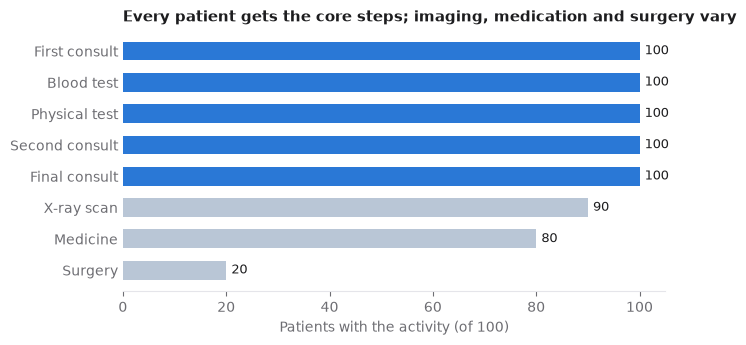

In [3]:
order = df["concept:name"].value_counts()
cases_per_activity = df.groupby("concept:name")["case:concept:name"].nunique().reindex(order.index)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(order.index[::-1], cases_per_activity[::-1], color=[SOFT if v < 100 else ACCENT for v in cases_per_activity[::-1]], height=0.6)
for y, v in enumerate(cases_per_activity[::-1]):
    ax.text(v + 1, y, str(v), va="center", fontsize=9)
ax.set_xlabel("Patients with the activity (of 100)")
ax.set_title("Every patient gets the core steps; imaging, medication and surgery vary")
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
save = lambda name: plt.gcf().savefig(FIG / f"{name}.png")
save("01_activity_coverage")

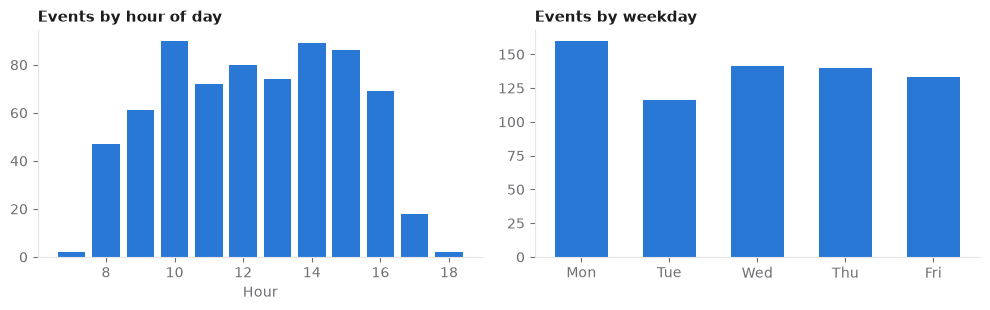

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
by_hour = df["time:timestamp"].dt.hour.value_counts().sort_index()
axes[0].bar(by_hour.index, by_hour.values, color=ACCENT, width=0.8)
axes[0].set(title="Events by hour of day", xlabel="Hour")
by_day = df["time:timestamp"].dt.dayofweek.value_counts().sort_index()
axes[1].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"][: len(by_day)], by_day.values, color=ACCENT, width=0.6)
axes[1].set(title="Events by weekday")
fig.tight_layout()
save("02_time_patterns")

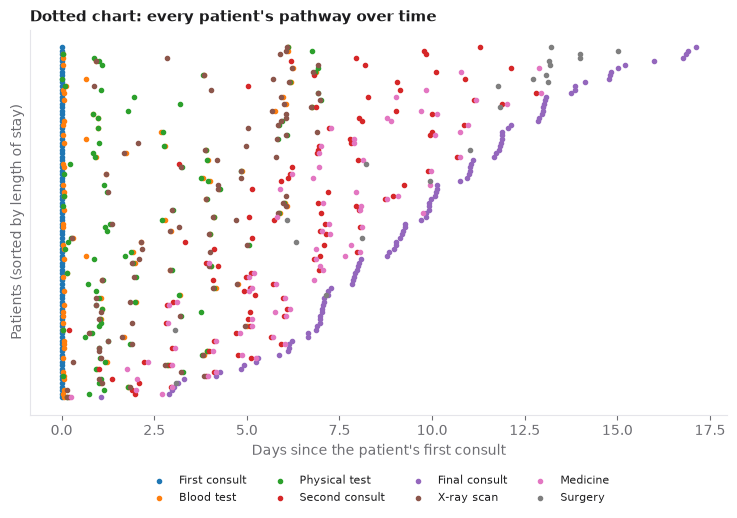

In [5]:
cases = df.groupby("case:concept:name")["relative_days"].max().sort_values().index
pos = {c: i for i, c in enumerate(cases)}
acts = list(order.index)
cmap = plt.get_cmap("tab10")
fig, ax = plt.subplots(figsize=(9, 5))
for k, a in enumerate(acts):
    sub = df[df["concept:name"] == a]
    ax.scatter(sub["relative_days"], sub["case:concept:name"].map(pos), s=9, color=cmap(k), label=a)
ax.set(xlabel="Days since the patient's first consult", ylabel="Patients (sorted by length of stay)", yticks=[])
ax.set_title("Dotted chart: every patient's pathway over time")
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.13))
save("03_dotted_chart")

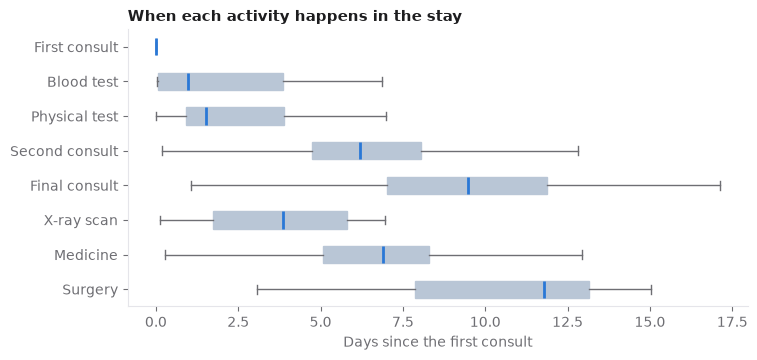

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
data = [df.loc[df["concept:name"] == a, "relative_days"] for a in acts]
ax.boxplot(data, vert=False, tick_labels=acts, widths=0.5, patch_artist=True,
           boxprops=dict(facecolor=SOFT, color=SOFT), medianprops=dict(color=ACCENT, lw=2),
           whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED), flierprops=dict(markersize=3, markeredgecolor=MUTED))
ax.invert_yaxis()
ax.set_xlabel("Days since the first consult")
ax.set_title("When each activity happens in the stay")
save("04_activity_timing")

org:resource
Doctor 1    158
Lab         100
Doctor 2     92
Pharmacy     80
Nurse 1      57
Doctor 3     50
Team 2       50
Nurse 2      43
Team 1       40
Doctor 4      7
Doctor 5      5
Doctor 6      5
Doctor 7      3
Name: count, dtype: int64

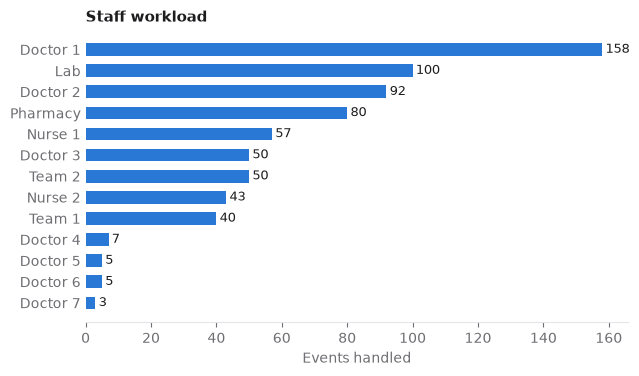

In [7]:
res = df["org:resource"].value_counts()
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(res.index[::-1], res.values[::-1], color=ACCENT, height=0.6)
for y, v in enumerate(res.values[::-1]):
    ax.text(v + 1, y, str(v), va="center", fontsize=9)
ax.set_xlabel("Events handled")
ax.set_title("Staff workload")
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
save("05_resource_workload")
res

## 3. Process discovery

In [8]:
dfg, start, end = pm4py.discover_dfg(log)
pm4py.save_vis_dfg(dfg, start, end, str(FIG / "06_dfg_frequency.png"))
perf_dfg, start, end = pm4py.discover_performance_dfg(log)
pm4py.save_vis_performance_dfg(perf_dfg, start, end, str(FIG / "07_dfg_performance.png"))
sorted(dfg.items(), key=lambda kv: -kv[1])[:10]

[(('Medicine', 'Final consult'), 80),
 (('Second consult', 'Medicine'), 80),
 (('First consult', 'Blood test'), 40),
 (('Physical test', 'Second consult'), 36),
 (('Blood test', 'Physical test'), 35),
 (('Blood test', 'Second consult'), 33),
 (('First consult', 'Physical test'), 33),
 (('Physical test', 'Blood test'), 33),
 (('Blood test', 'X-ray scan'), 32),
 (('X-ray scan', 'Physical test'), 32)]

In [9]:
tree = pm4py.discover_process_tree_inductive(log)
pm4py.save_vis_process_tree(tree, str(FIG / "08_process_tree.png"))
bpmn = pm4py.convert_to_bpmn(tree)
pm4py.save_vis_bpmn(bpmn, str(FIG / "09_bpmn.png"))
heu = pm4py.discover_heuristics_net(log)
pm4py.save_vis_heuristics_net(heu, str(FIG / "10_heuristic_net.png"))
print(tree)

->( 'First consult', +( 'Blood test', X( tau, 'X-ray scan' ), 'Physical test' ), 'Second consult', X( 'Surgery', 'Medicine' ), 'Final consult' )


## 4. Comparing discovery algorithms

In [10]:
nets = {
    "Alpha miner": pm4py.discover_petri_net_alpha(log),
    "Inductive miner": pm4py.discover_petri_net_inductive(log),
    "Heuristic miner": pm4py.discover_petri_net_heuristics(log),
}
pm4py.save_vis_petri_net(*nets["Inductive miner"], str(FIG / "11_petri_net_inductive.png"))
rows = []
for name, (net, im, fm) in nets.items():
    rows.append({
        "Miner": name,
        "Fitness": pm4py.fitness_token_based_replay(log, net, im, fm)["log_fitness"],
        "Precision": pm4py.precision_token_based_replay(log, net, im, fm),
        "Generalization": pm4py.algo.evaluation.generalization.algorithm.apply(log, net, im, fm),
        "Simplicity": pm4py.algo.evaluation.simplicity.algorithm.apply(net),
    })
quality = pd.DataFrame(rows).set_index("Miner").round(3)
quality.to_csv(FIG / "miner_quality.csv")
quality

,Fitness,Precision,Generalization,Simplicity
Miner,,,,
Alpha miner,0.99,0.983,0.882,0.818
Inductive miner,1.00,0.984,0.860,0.760
Heuristic miner,0.99,0.983,0.882,0.818


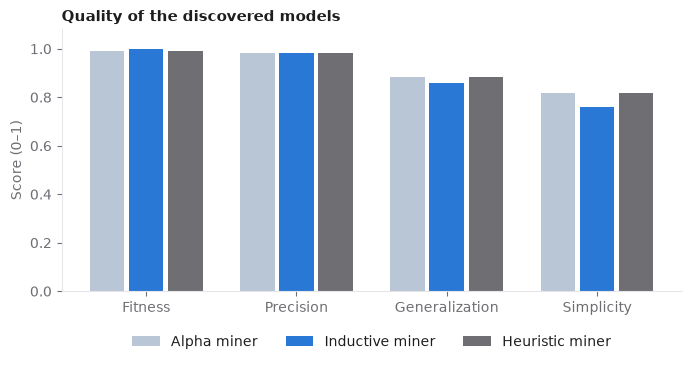

In [11]:
metrics = ["Fitness", "Precision", "Generalization", "Simplicity"]
fig, ax = plt.subplots(figsize=(8, 3.4))
w = 0.26
colors = {"Alpha miner": SOFT, "Inductive miner": ACCENT, "Heuristic miner": MUTED}
for i, (name, row) in enumerate(quality.iterrows()):
    xs = [m + (i - 1) * w for m in range(len(metrics))]
    ax.bar(xs, row[metrics], width=w - 0.03, color=colors[name], label=name)
ax.set_xticks(range(len(metrics)), metrics)
ax.set_ylim(0, 1.08)
ax.set_ylabel("Score (0–1)")
ax.set_title("Quality of the discovered models")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
save("12_miner_quality")

## 5. Conclusions

1. **Typical pathway:** first consult → blood test and physical examination (with optional X-ray/MRI) → second consult → medication *or* surgery → final consult.
2. **Core steps are universal:** blood tests and physical examinations appear for every patient, while imaging, medication and surgery depend on the case.
3. **The key decision** is made at the second consult, where most patients go on to medication and a minority to surgery.
4. **Discovery algorithms trade off quality dimensions:** the inductive miner fits the log perfectly but yields a more complex model, while the alpha and heuristic miners give simpler, better-generalising models.

*Limitation:* the event log is artificial and created for teaching, so the findings illustrate the method rather than a real hospital.